# Step 12: Medical Slice Transformer on every tumour slice (GPU T4, ~45-75 min)
Step 10 fine-tuned DINOv2 end to end on 2D slices: the best epoch was 1-2, train AUC only 0.64, each run ~12
GPU-minutes, val 0.61 (below the subtype lookup). The **Medical Slice Transformer** (Mueller-Franzes et al., Sci Rep
2025: AUC 0.94 vs 0.91 for a 3D ResNet on breast MRI) keeps a 2D DINOv2 per slice and learns how to combine the
slices with one transformer layer. Here:

1. **Embeddings**: frozen DINOv2 on every tumour slice (up to 32), `sub` input, plus 4 augmented views per slice
   (crop scale, flips, rotations, intensity), so the small model trained on top still sees augmentation.
2. **Slice models** (only these are trained; minutes per model, so each is cross-validated 3 x 5 times):
   - `mean`: masked mean of the slice tokens (step 10's averaging, but all slices and trainable)
   - `attn_mil`: gated attention pooling: learned per-slice weights, saved for inspection
   - `mst`: [CLS] + 1 transformer layer: the MST design
   - `mst_noaux`: MST without the auxiliary HR / HER2 heads (multi-task ablation)
   - `mst_subtype`: MST with the subtype one-hot fed to the head (subtype-aware deep model)
   Every slice token also carries its position in the tumour and its tumour area (from our cleaned mask).
3. **Evaluation**: the same repeated outer CV as steps 11 and 13 (OOF AUC on all train patients, per subtype /
   cohort), early stopping on an inner 15% split of each training fold; val = the mean of all fold models.

Kaggle setup: Accelerator **GPU T4 x2**, Internet **ON**.
**+ Add Input**:
- the caches (the best one attached per cohort is used and printed): **`mnj-cache2-ispy1/-ispy2/-duke`** (raw,
  step 2: nothing clipped) if you have them, else `mnj-cache-v2` or `mnj-cache-ispy1/-ispy2/-duke` (uint8, clipped:
  the code works, but the brightest enhancement is lost);
- the code: the **`mnj-code-vaib` Dataset, NEW version** (the zip made on 2026-11-04 or later has the steps 11-13
  code; the setup cell stops with a clear message if the attached code is older).

Run with `DEBUG = True` first (a few minutes, 40 patients per split) to check the notebook, then `DEBUG = False`
with **Save Version -> Save & Run All (Commit)**. Every step prints a timestamped `[...]` line. Results: Output tab,
`results/<PERSON>/<step>/`. Background and rationale: `docs/vaib/STEPS_11_13.md`.

In [1]:
# ==== PARAMETERS (edit these) ====
REPO = "AkulaReddy/MRI_chemo_response"
GIT_TAG = "vaib"           # branch (or tag) to clone
PERSON = ""               # optional: "A", "B" or "C" -> results/<PERSON>/ (empty -> results/vaib/)
STEP = "step12"
PREFER = "v2"
BACKBONE = "dinov2_b"
VIT_NORM = "sub"
N_AUG = 4                    # augmented views per slice (+ the clean one)
MAX_SLICES = 32
VARIANTS = ["mean", "attn_mil", "mst", "mst_noaux", "mst_subtype"]
REPEATS = 3                  # outer CV repeats per variant (x 5 folds)
EPOCHS = 40                  # maximum epochs (early stopping on an inner 15% split of each training fold)
EXTRA_PIP = []
TIME_BUDGET_H = 11.0
DEBUG = False                # True: 40 patients per split, 1 augmented view, 1 repeat, 5 epochs
PUSH_RESULTS = False
NOTEBOOK_NAME = "step12"

In [2]:
# ==== SETUP (do not edit): get the repo code, install requirements ====
import base64, glob, json, os, shutil, subprocess, sys, zipfile
if PERSON not in ("A", "B", "C"):           # only names the results folder
    PERSON = "vaib"
    print('PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)')
NEEDS = "src/vitonly/rcv.py"               # the steps 11-13 code (in the mnj-code-vaib zip made on 2026-11-04 or later)
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as e:
    print("no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached):",
          type(e).__name__)

def git(*args, cwd="/tmp/repo"):
    """git with the token as a one-off header (never stored in .git/config or the output)."""
    if not _tok:
        raise RuntimeError("no GITHUB_TOKEN secret: git push/pull is not available")
    hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={hdr}", *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(_tok, "***")
    if r.returncode:
        raise RuntimeError(f"git {args[0]} failed:\n{out}")
    return out

def _find_code():
    """An attached code Dataset that already has the steps 11-13 code (an unpacked folder or the uploaded zip)."""
    hits = [h for d in range(1, 8) for h in glob.glob("/kaggle/input/" + "*/" * d + NEEDS)]
    if not hits:
        for z in [z for d in range(1, 6) for z in glob.glob("/kaggle/input/" + "*/" * d + "mnj-code-vaib*.zip")]:
            zipfile.ZipFile(z).extractall("/tmp/code_zip")
        hits = glob.glob("/tmp/code_zip/**/" + NEEDS, recursive=True)
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

shutil.rmtree("/tmp/repo", ignore_errors=True)
code_root = _find_code()
if code_root:                               # 1) the attached code Dataset with the new code wins
    shutil.copytree(code_root, "/tmp/repo")
    print("code: attached Dataset", code_root)
elif _tok:                                  # 2) or clone the branch from GitHub
    git("clone", "--quiet", "--depth", "1", "--branch", GIT_TAG, f"https://github.com/{REPO}.git", "/tmp/repo", cwd="/tmp")
    print("code: GitHub", REPO, GIT_TAG, git("log", "-1", "--format=%h %s"))
    if not os.path.exists(f"/tmp/repo/{NEEDS}"):
        raise SystemExit(f"branch {GIT_TAG} has no steps 11-13 code ({NEEDS}). Attach the NEW mnj-code-vaib zip "
                         "(+ Add Input -> Your Datasets -> mnj-code-vaib, latest version), or set GIT_TAG to a branch with it.")
else:
    print("attached inputs:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") <= 5:
            print("  ", root, dirs[:6], files[:4])
        else:
            dirs[:] = []
    raise SystemExit(
        "\nThe notebook can't find the steps 11-13 code. Upload the new mnj-code-vaib.zip as a NEW VERSION of the\n"
        "mnj-code-vaib Dataset, then + Add Input -> Your Datasets -> mnj-code-vaib (latest version) and Run All again.")
os.chdir("/tmp/repo")
sys.path.insert(0, "/tmp/repo")         # so `from src...` works in this kernel
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-kaggle.txt"], check=True)
for pkg in EXTRA_PIP:                   # optional extras: a failed install is reported, never fatal
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    print(f"pip install {pkg}:", "ok" if r.returncode == 0 else "FAILED (the step that needs it is skipped)\n" + r.stderr[-500:])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)
no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached): BackendError
code: attached Dataset /kaggle/input/datasets/a15chvaibhav/mnj-code-vaib/MRI_chemo_response
torch 2.11.0+cu130 | GPU: Tesla T4


In [3]:
# ==== HELPERS (do not edit): training runs, prediction files, comparisons ====
import glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import evaluation as ev, stats
from src.train import find_caches
from src.data.metadata import patient_table
COH = ["ispy1", "ispy2", "duke"]
OUT = f"/kaggle/working/results/{PERSON}/{STEP}"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
RUNS_JSON = {}
pd.set_option("display.width", 250, "display.max_columns", 40)

def budget_left():
    return TIME_BUDGET_H - (time.time() - T0) / 3600

def say(msg):
    """Timestamped progress line (elapsed and remaining budget), flushed so it shows in the Kaggle log at once."""
    el = (time.time() - T0) / 3600
    print(f"[{time.strftime('%H:%M:%S')} | {el:.2f} h elapsed, {budget_left():.2f} h left] {msg}", flush=True)

def run_cmd(cmd):
    """Run a training subprocess and stream its output line by line into this notebook (subprocess.run alone
    shows nothing until it ends, and the child's stdout is block-buffered without PYTHONUNBUFFERED)."""
    print("\n" + " ".join(cmd), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait():
        raise subprocess.CalledProcessError(p.returncode, cmd)
    say(f"finished in {(time.time() - t) / 60:.1f} min")

def check_caches(version):
    caches = find_caches(["/kaggle/input", "/kaggle/working"])
    info = {c: json.load(open(f"{d}/cache_meta.json")).get("builder_version", 1) for c, d in caches.items()}
    print("caches:", {c: f"builder v{v}: {caches[c]}" for c, v in info.items()})
    if version is not None:
        bad = {c: v for c, v in info.items() if v != version}
        assert not bad and len(info) == 3, (f"need cache builder v{version} for all 3 cohorts (attach mnj-cache-v2); "
                                            f"found {info}")
    return caches

def _copy(d, label):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    for f in ("val_preds.csv", "metrics.json", "log.csv", "config_resolved.yaml", "export_preds.csv",
              "train_preds.csv", "encoder.json"):
        if os.path.exists(f"{d}/{f}"):
            shutil.copy(f"{d}/{f}", f"{OUT}/{label}/{f}")

def train(config, seed, sets=(), label=None, cohorts=None):
    """One src.train run (B3 / F2 ...) -> (run_dir, metrics). Its small files are copied to OUT/<label>/."""
    cmd = [sys.executable, "-m", "src.train", "--config", config, "--seed", str(seed), "--out", "/kaggle/working/runs"]
    if CACHE_VERSION is not None: cmd += ["--cache-version", str(CACHE_VERSION)]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d, json.load(open(f"{d}/metrics.json"))

def finetune(config, seed, sets=(), label=None, cohorts=None):
    """One src.vitonly.finetune run (our pipeline: ViT-only vo_base / fusion vo_fusion) -> run_dir."""
    cmd = [sys.executable, "-m", "src.vitonly.finetune", "--config", config, "--seed", str(seed),
           "--cache-root", "/kaggle/input", "/kaggle/working", "--out", "/kaggle/working/runs"]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d

def note_runs(key, dirs):
    """label -> run folder names, in OUT/runs.json: step 8 uses it to find the checkpoints."""
    RUNS_JSON[key] = [os.path.basename(d) for d in dirs]
    json.dump(RUNS_JSON, open(f"{OUT}/runs.json", "w"), indent=1)

def preds_of(dirs):
    fr = [ev.load_preds(f"{d}/val_preds.csv") for d in dirs]
    return fr[0] if len(fr) == 1 else ev.ensemble(fr)

def save_preds(label, df):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    df.to_csv(f"{OUT}/{label}/val_preds.csv", index=False)
    return df

def repo_preds(pattern):
    hits = sorted(glob.glob(f"results/*/{pattern}/val_preds.csv"))
    return preds_of([os.path.dirname(h) for h in hits]) if hits else None

def train_auc(d):
    """AUC on the training patients from export_preds.csv (B3 exports after training): the overfitting gap."""
    f = f"{d}/export_preds.csv"
    if not os.path.exists(f): return np.nan
    e = pd.read_csv(f); e = e[e.split == "train"]
    return stats.auc(e.label, e.prob)

def vo_train_auc(d):
    """Training-set AUC of a src.vitonly run (metrics.json): the overfitting gap."""
    return json.load(open(f"{d}/metrics.json"))["val"].get("train_auc", np.nan)

def compare(preds, ref):
    """One row per model on the patients all models share: AUC (DeLong CI), AUPRC, Brier, ECE, the 90%-spec
    operating point (threshold chosen on these same val patients: optimistic), and the paired DeLong test
    and paired bootstrap of the AUC difference vs `ref`."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    rows = []
    for k, d in preds.items():
        r = {"model": k, **ev.summary_row(d.label, d.prob)}
        if k != ref and ref in preds:
            y = preds[ref].label
            dl = ev.delong(y, preds[ref].prob, d.prob)
            pb = stats.paired_bootstrap_auc_diff(y, preds[ref].prob, d.prob)
            r.update(diff_vs_ref=dl["diff"], delong_ci_lo=dl["ci"][0], delong_ci_hi=dl["ci"][1], delong_p=dl["p"],
                     boot_p=pb["p"])
        rows.append(r)
    cols = ["model", "n", "pcr", "auc", "ci_lo", "ci_hi", "auprc", "brier", "ece", "sens@90spec", "ppv@90spec",
            "npv@90spec", "diff_vs_ref", "delong_ci_lo", "delong_ci_hi", "delong_p", "boot_p"]
    t = pd.DataFrame(rows)
    return t[[c for c in cols if c in t]]

def subtype_wide(preds, by="subtype"):
    """AUC (95% CI) per subtype (or cohort) for every model, all on the same patients; n / pCR+ per group."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    tabs = {k: ev.subgroup_table(d, by).set_index(by) for k, d in preds.items()}
    first = next(iter(tabs.values()))
    out = pd.DataFrame({"n": first.n.astype(int), "pCR+": first.pcr.astype(int)})
    for k, t in tabs.items():
        out[k] = [f"{a:.3f} ({lo:.2f}-{hi:.2f})" if a == a else "n/a (one class)"
                  for a, lo, hi in zip(t.auc, t.ci_lo, t.ci_hi)]
    return out

B1_VAL = repo_preds("b1_lr_s0_*")                       # clinical + tumour size, logistic regression (val 0.653)
B0_VAL = repo_preds("b0_lr_s0_*")                       # clinical only (val 0.639)
AKULA_B3_V2 = repo_preds("b3_vit_s0_1019-0302_*")       # Akula's B3 on cache v2 (val 0.559)
B3_V1 = repo_preds("b3_vit_s0_1009-1616_*")             # B3 on the old cache (val 0.530)
F2_V1 = repo_preds("f2_attn_s0_1009-1605_*")            # fusion on the old cache (val 0.690)
print("reference predictions from the repo:", {k: v is not None for k, v in
      dict(B1=B1_VAL, B0=B0_VAL, B3_v2_Akula=AKULA_B3_V2, B3_v1=B3_V1, F2_v1=F2_V1).items()})

reference predictions from the repo: {'B1': True, 'B0': True, 'B3_v2_Akula': True, 'B3_v1': True, 'F2_v1': True}


In [4]:
# ==== which cache is used for each cohort ====
from src.vitonly.slabs import find_caches as vo_find_caches, cache_label
VO_CACHES = vo_find_caches(["/kaggle/input", "/kaggle/working"], PREFER)
say(f"caches found: {len(VO_CACHES)} cohorts")
for c in COH:
    print(f"  {c:6s}", f"{cache_label(VO_CACHES[c])}  {VO_CACHES[c]}" if c in VO_CACHES else "MISSING -> left out", flush=True)
if not VO_CACHES:
    raise SystemExit("no cache attached: + Add Input -> mnj-cache2-* / mnj-cache-v2 / mnj-cache-*")
if any(cache_label(d).startswith("v1") for d in VO_CACHES.values()):
    print("NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. "
          "Raw mnj-cache2-* caches (step 2) are exact.", flush=True)

[11:32:58 | 0.00 h elapsed, 11.00 h left] caches found: 3 cohorts
  ispy1  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
  ispy2  v1 uint8 builder 1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
  duke   v1 uint8 builder 1  /kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke
NOTE: uint8 cache(s): the brightest enhancement is clipped, so intensity / PE features are underestimated. Raw mnj-cache2-* caches (step 2) are exact.


## 1. Frozen DINOv2 embeddings of every tumour slice, with augmented views (GPU, ~15-25 min)

In [5]:
EMB_DIR = f"{OUT}/embeddings"
EMB = f"{EMB_DIR}/slices_{BACKBONE}_{VIT_NORM}.npz"
cmd = [sys.executable, "-m", "src.vitonly.slice_embed", "--out", EMB_DIR, "--backbone", BACKBONE, "--norm", VIT_NORM,
       "--n-aug", str(1 if DEBUG else N_AUG), "--max-slices", str(MAX_SLICES), "--prefer", PREFER,
       "--cache-root", "/kaggle/input", "/kaggle/working"]
if DEBUG: cmd += ["--limit", "40"]
say("1. embeddings start (progress every 100 patients)")
run_cmd(cmd)

[11:32:58 | 0.00 h elapsed, 11.00 h left] 1. embeddings start (progress every 100 patients)

/usr/bin/python3 -m src.vitonly.slice_embed --out /kaggle/working/results/vaib/step12/embeddings --backbone dinov2_b --norm sub --n-aug 4 --max-slices 32 --prefer v2 --cache-root /kaggle/input /kaggle/working
[data] 1 of 1099 patients have no cache entry, dropped (first: ['Breast_MRI_577'])
[slice_embed 11:33:01 +0.0 min] 1275 patients (train + val) | caches ispy1: v1 uint8 builder 1, ispy2: v1 uint8 builder 1, duke: v1 uint8 builder 1 | dinov2_b, norm sub, crop tumor, 5 view(s), up to 32 slices

Loading weights: 100%|██████████| 223/223 [00:00<00:00, 2696.32it/s]
[slice_embed 11:34:31 +1.5 min]   100/1275 patients, 0.7 min, eta 8.7 min
[slice_embed 11:35:08 +2.1 min]   200/1275 patients, 1.4 min, eta 7.3 min
[slice_embed 11:35:46 +2.8 min]   300/1275 patients, 2.0 min, eta 6.5 min
[slice_embed 11:36:28 +3.4 min]   400/1275 patients, 2.7 min, eta 5.9 min
[slice_embed 11:37:11 +4.2 min]   500/12

## 2. Train and cross-validate every slice model

In [6]:
SC = f"{OUT}/mst"
cmd = [sys.executable, "-m", "src.vitonly.mst", "--embeddings", EMB, "--out", SC, "--variants", *VARIANTS,
       "--repeats", str(1 if DEBUG else REPEATS), "--epochs", str(5 if DEBUG else EPOCHS)]
say("2. slice models start (a line every 5 folds and per variant)")
run_cmd(cmd)
RES = pd.read_csv(f"{SC}/results.csv")
CMPS = pd.read_csv(f"{SC}/comparisons.csv")
VAL = pd.read_csv(f"{SC}/val_preds.csv", dtype={"pid": str})
say(f"2. done: {len(RES)} rows in {SC}/results.csv")

[11:42:52 | 0.17 h elapsed, 10.83 h left] 2. slice models start (a line every 5 folds and per variant)

/usr/bin/python3 -m src.vitonly.mst --embeddings /kaggle/working/results/vaib/step12/embeddings/slices_dinov2_b_sub.npz --out /kaggle/working/results/vaib/step12/mst --variants mean attn_mil mst mst_noaux mst_subtype --repeats 3 --epochs 40
[mst 11:42:55 +0.0 min] 1275 patients (train 1098, val 177), 33753 slices, 5 view(s) per slice, embedding 768 | device cuda:0 | args {'embeddings': '/kaggle/working/results/vaib/step12/embeddings/slices_dinov2_b_sub.npz', 'out': '/kaggle/working/results/vaib/step12/mst', 'variants': ['mean', 'attn_mil', 'mst', 'mst_noaux', 'mst_subtype'], 'repeats': 3, 'folds': 5, 'epochs': 40, 'seed': 0, 'cpu': False}
[mst 11:42:59 +0.1 min]   subtype lookup: oof 0.639 | val 0.662
[mst 11:42:59 +0.1 min] variant mean: 3 x 5 folds
[mst 11:43:30 +0.6 min]     mean: fold 5/15, fold AUC so far 0.592, best inner epoch 8.0
[mst 11:43:50 +0.9 min]     mean: fold 10/15, 

## 3. Summary: which slice model is best, and what do the attention weights look at?

       variant  best_epoch  cv_auc  cv_auc_sd  oof_auc  oof_within_subtype  oof_within_cohort  val_auc  val_ci_lo  val_ci_hi  val_within_subtype  val_her2pos  val_hrpos_her2neg  val_tn  oof_vs_lookup  oof_vs_lookup_p
subtype_lookup         NaN   0.658      0.023    0.639               0.435              0.649    0.662      0.575      0.740               0.500        0.500              0.500   0.500            NaN              NaN
          mean       5.267   0.598      0.044    0.607               0.596              0.616    0.582      0.494      0.672               0.571        0.608              0.473   0.631         -0.032            0.220
      attn_mil       7.333   0.601      0.045    0.610               0.599              0.617    0.586      0.499      0.672               0.567        0.607              0.468   0.626         -0.029            0.270
           mst       6.933   0.603      0.038    0.596               0.587              0.622    0.582      0.491      0.670        

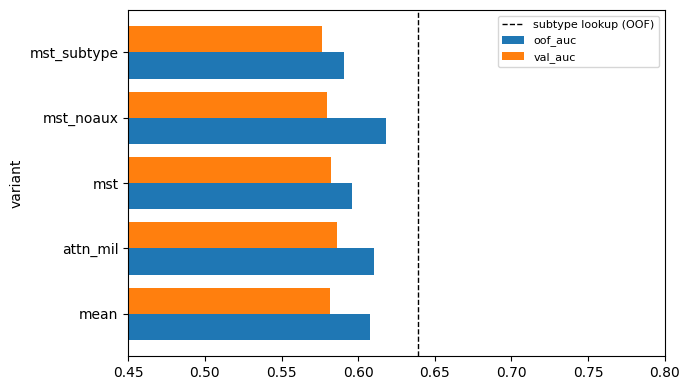


Paired comparisons (b - a):
                        comparison  oof_auc_a  oof_auc_b  oof_diff  oof_p  val_auc_a  val_auc_b  val_diff  val_p
             mean -> attention MIL      0.607      0.610     0.003  0.784      0.582      0.586     0.004  0.730
                       mean -> MST      0.607      0.596    -0.011  0.252      0.582      0.582     0.001  1.000
              attention MIL -> MST      0.610      0.596    -0.014  0.192      0.586      0.582    -0.004  0.660
 MST without -> with HR/HER2 heads      0.618      0.596    -0.022  0.022      0.580      0.582     0.002  0.780
   subtype lookup -> MST + subtype      0.639      0.591    -0.048  0.052      0.662      0.576    -0.086  0.114
subtype lookup -> MST (image only)      0.639      0.596    -0.043  0.112      0.662      0.582    -0.080  0.152


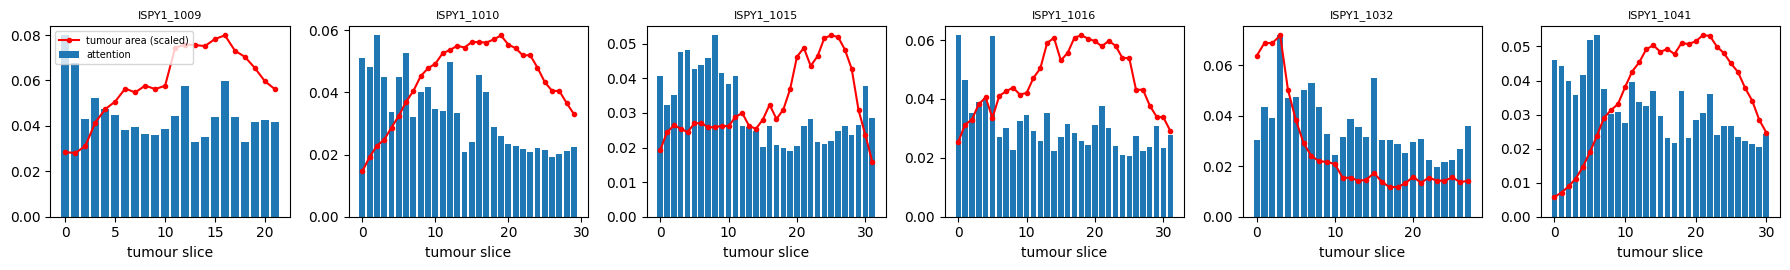

[11:51:15 | 0.30 h elapsed, 10.70 h left] top 3 variants by CV: mst_noaux, mst_subtype, mst
                   model   n  pcr   auc  ci_lo  ci_hi  auprc  brier   ece  sens@90spec  ppv@90spec  npv@90spec  diff_vs_ref  delong_ci_lo  delong_ci_hi  delong_p  boot_p
 B1 LR (clinical + size) 177   53 0.653  0.566  0.740  0.448  0.196 0.041        0.245       0.520       0.737       -0.009        -0.077         0.058     0.787   0.772
          subtype lookup 177   53 0.662  0.579  0.745  0.411  0.198 0.061        0.000         NaN       0.701          NaN           NaN           NaN       NaN     NaN
F2 fusion v1 (old cache) 177   53 0.690  0.603  0.777  0.516  0.194 0.080        0.283       0.556       0.747        0.028        -0.001         0.057     0.058   0.068
       step12: mst_noaux 177   53 0.580  0.489  0.671  0.345  0.218 0.091        0.057       0.200       0.691       -0.082        -0.196         0.032     0.159   0.163
     step12: mst_subtype 177   53 0.576  0.485  0.668  0.3

In [7]:
cols = ["variant", "best_epoch", "cv_auc", "cv_auc_sd", "oof_auc", "oof_within_subtype", "oof_within_cohort",
        "val_auc", "val_ci_lo", "val_ci_hi", "val_within_subtype", "val_her2pos", "val_hrpos_her2neg", "val_tn",
        "oof_vs_lookup", "oof_vs_lookup_p"]
print(RES[[c for c in cols if c in RES]].round(3).to_string(index=False))
r = RES.set_index("variant")
ax = r[["oof_auc", "val_auc"]].drop(index="subtype_lookup", errors="ignore").plot.barh(figsize=(7, 4), width=0.8)
ax.axvline(float(r.loc["subtype_lookup", "oof_auc"]), color="k", ls="--", lw=1, label="subtype lookup (OOF)")
ax.set_xlim(0.45, 0.8); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/auc_by_variant.png", dpi=120); plt.show()
print("\nPaired comparisons (b - a):")
print(CMPS[["comparison", "oof_auc_a", "oof_auc_b", "oof_diff", "oof_p", "val_auc_a", "val_auc_b", "val_diff", "val_p"]]
      .round(3).to_string(index=False))
if os.path.exists(f"{SC}/attention_val.csv"):          # which slices does attention-MIL look at?
    from src.vitonly.slice_embed import load
    att, E = pd.read_csv(f"{SC}/attention_val.csv", dtype={"pid": str}), load(EMB)
    pos = {p: i for i, p in enumerate(E["pid"].astype(str))}
    show = [p for p in att.pid.unique() if p in pos][:6]
    if show:
        fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 2.8), squeeze=False)
        for ax, p in zip(axes[0], show):
            a, b = E["offsets"][pos[p]], E["offsets"][pos[p] + 1]
            w = att[att.pid == p].weight.to_numpy()
            area = E["area"][a:b] / max(E["area"][a:b].max(), 1)
            ax.bar(range(len(w)), w, label="attention"); ax.plot(range(len(area)), area * w.max(), "r.-", label="tumour area (scaled)")
            ax.set_title(p, fontsize=8); ax.set_xlabel("tumour slice")
        axes[0][0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/attention_examples.png", dpi=120); plt.show()
ok = RES[RES.variant != "subtype_lookup"].sort_values("cv_auc", ascending=False)
BEST = {f"{v}": v for v in ok.variant.head(3)}
say("top 3 variants by CV: " + ", ".join(BEST))

# ---- the best configurations against the team's models on val (paired DeLong vs the subtype lookup) ----
def as_preds(frame, col):
    return frame[["pid", "cohort", "label"]].assign(prob=frame[col].values)
preds = {"B1 LR (clinical + size)": B1_VAL, "subtype lookup": as_preds(VAL, "subtype_lookup"),
         "F2 fusion v1 (old cache)": F2_V1}
preds.update({f"{STEP}: {name}": as_preds(VAL, col) for name, col in BEST.items() if col in VAL})
CMP = compare(preds, "subtype lookup")
print(CMP.round(3).to_string(index=False))
CMP.to_csv(f"{OUT}/comparison_vs_team.csv", index=False)
ours = {k: v for k, v in preds.items() if k.startswith(STEP)}
if ours:
    print("\nper subtype (val):"); print(subtype_wide(ours).to_string())
    print("\nper cohort (val):"); print(subtype_wide(ours, by="cohort").to_string())

## 4. Results file

In [8]:
from src.vitonly.rcv import md_table
txt = open(f"{SC}/RESULTS.md").read()
txt += "\n## Best variants vs the team's models (val, paired DeLong vs the subtype lookup)\n\n" + md_table(CMP) + "\n"
open(f"{OUT}/RESULTS_step12.md", "w").write(txt)
say(f"wrote {OUT}/RESULTS_step12.md -- download it from the Output tab (or PUSH_RESULTS)")

[11:51:43 | 0.31 h elapsed, 10.69 h left] wrote /kaggle/working/results/vaib/step12/RESULTS_step12.md -- download it from the Output tab (or PUSH_RESULTS)


In [9]:
# ==== PUSH the small result files to the vaib branch (results/<PERSON>/...) ====
if PUSH_RESULTS and not _tok:
    print("PUSH_RESULTS needs the GITHUB_TOKEN secret; download results/ from the Output tab instead")
elif PUSH_RESULTS and not DEBUG:
    git("config", "user.name", f"Person {PERSON} (Kaggle)")
    git("config", "user.email", "kaggle@users.noreply.github.com")
    for attempt in range(3):
        git("fetch", "--quiet", "--depth", "1", "origin", f"+refs/heads/{GIT_TAG}:refs/remotes/origin/{GIT_TAG}")
        git("checkout", "--quiet", "-f", "-B", GIT_TAG, f"origin/{GIT_TAG}")
        shutil.copytree(f"/kaggle/working/results/{PERSON}", f"results/{PERSON}", dirs_exist_ok=True)
        git("add", f"results/{PERSON}")
        print(git("commit", "-m", f"results: {PERSON} {NOTEBOOK_NAME} ({GIT_TAG})"))
        try:
            git("push", "--quiet", "origin", GIT_TAG); print("pushed to", GIT_TAG); break
        except RuntimeError as e:
            print(f"push attempt {attempt + 1} failed:", e)
    else:
        print("NOT pushed: download results/ from the Output tab")